In [1]:
import pandas as pd
import numpy as np

# Load feature-engineered dataset
df_model = pd.read_parquet(
    "../data/processed/uber_feature_engineered.parquet"
)

print("Dataset shape:", df_model.shape)

display(df_model.head())

Dataset shape: (195699, 30)


,key,fare_amount,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,haversine_distance_km,is_zero_distance,...,pickup_year,is_weekend,is_rush_hour,road_distance_ratio,distance_difference_km,estimated_speed_kmh,pickup_location_lat,pickup_location_lon,dropoff_location_lat,dropoff_location_lon
0,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06+00:00,1,-73.999817,40.738354,-73.999512,40.723217,1.683323,False,...,2015,0,0,1.245691,0.413577,26.413016,40.738,-74.000,40.723,-74.000
1,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56+00:00,1,-73.994355,40.728225,-73.994710,40.750325,2.457590,False,...,2009,0,1,1.383469,0.942410,26.620270,40.728,-73.994,40.750,-73.995
2,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00+00:00,1,-74.005043,40.740770,-73.962565,40.772647,5.036377,False,...,2009,0,1,1.274210,1.381023,29.633966,40.741,-74.005,40.773,-73.963
3,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21+00:00,3,-73.976124,40.790844,-73.965316,40.803349,1.661683,False,...,2009,0,0,1.376616,0.625817,35.929319,40.791,-73.976,40.803,-73.965
4,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00+00:00,5,-73.925023,40.744085,-73.973082,40.761247,4.475450,False,...,2014,0,0,1.116558,0.521650,40.691156,40.744,-73.925,40.761,-73.973


In [2]:
df_model = df_model[
    df_model["fare_amount"] > 0
].copy()

print("Clean dataset shape:", df_model.shape)
print("Non-positive fares:",
      (df_model["fare_amount"] <= 0).sum())

Clean dataset shape: (195680, 30)
Non-positive fares: 0


In [3]:
# OSRM route missing indicator
df_model["osrm_route_missing"] = (
    df_model["road_distance_km"].isnull()
).astype(int)

# Road distance ratio missing indicator
df_model["road_distance_ratio_missing"] = (
    df_model["road_distance_ratio"].isnull()
).astype(int)

# Estimated speed missing indicator
df_model["estimated_speed_missing"] = (
    df_model["estimated_speed_kmh"].isnull()
).astype(int)

# Check results
print("Missing-value indicators:")
print(
    df_model[
        [
            "osrm_route_missing",
            "road_distance_ratio_missing",
            "estimated_speed_missing"
        ]
    ].sum()
)

print("\nDataset shape:", df_model.shape)

Missing-value indicators:
osrm_route_missing                1
road_distance_ratio_missing    1974
estimated_speed_missing        2273
dtype: int64

Dataset shape: (195680, 33)


Separate features (X) and target (y)  
In machine learning:  
- X: Input features used to make predictions.  
- y: The value we want to predict — taxi fare.  

In [4]:
# Target variable
y = df_model["fare_amount"].copy()

# Columns to exclude from model training
exclude_columns = [
    "key",
    "fare_amount",
    "has_nonpositive_fare",
    "route_id",
    "status",
    "pickup_datetime",
    "pickup_datetime_ny"
]

# Create feature matrix
X = df_model.drop(columns=exclude_columns)

# Display results
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
for i, col in enumerate(X.columns, start=1):
    print(f"{i}. {col}")

Feature matrix shape: (195680, 26)
Target shape: (195680,)

Feature columns:
1. passenger_count
2. pickup_longitude
3. pickup_latitude
4. dropoff_longitude
5. dropoff_latitude
6. haversine_distance_km
7. is_zero_distance
8. road_distance_km
9. road_duration_min
10. pickup_hour
11. pickup_day
12. pickup_day_of_week
13. pickup_month
14. pickup_year
15. is_weekend
16. is_rush_hour
17. road_distance_ratio
18. distance_difference_km
19. estimated_speed_kmh
20. pickup_location_lat
21. pickup_location_lon
22. dropoff_location_lat
23. dropoff_location_lon
24. osrm_route_missing
25. road_distance_ratio_missing
26. estimated_speed_missing


In [5]:
# Target variable
y = df_model["fare_amount"].copy()

# Columns to exclude
exclude_columns = [
    "key",
    "fare_amount",
    "has_nonpositive_fare",
    "route_id",
    "status",
    "pickup_datetime",
    "pickup_datetime_ny"
]

# Input features
X = df_model.drop(columns=exclude_columns)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Feature matrix shape: (195680, 26)
Target shape: (195680,)

Feature columns:
['passenger_count', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'haversine_distance_km', 'is_zero_distance', 'road_distance_km', 'road_duration_min', 'pickup_hour', 'pickup_day', 'pickup_day_of_week', 'pickup_month', 'pickup_year', 'is_weekend', 'is_rush_hour', 'road_distance_ratio', 'distance_difference_km', 'estimated_speed_kmh', 'pickup_location_lat', 'pickup_location_lon', 'dropoff_location_lat', 'dropoff_location_lon', 'osrm_route_missing', 'road_distance_ratio_missing', 'estimated_speed_missing']


Chronological train/test split  
We'll use the earlier 80% of trips for training and the latest 20% for testing.  

Why chronological? It simulates a real-world situation: training on historical taxi trips and predicting fares for future trips.  

In [6]:
# Sort records by pickup datetime
df_model = df_model.sort_values(
    "pickup_datetime"
).reset_index(drop=True)

# Define split point
split_index = int(len(df_model) * 0.80)

# Split features
X = df_model.drop(columns=exclude_columns)
y = df_model["fare_amount"]

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining date range:")
print(df_model["pickup_datetime"].iloc[0],
      "to",
      df_model["pickup_datetime"].iloc[split_index - 1])

print("\nTesting date range:")
print(df_model["pickup_datetime"].iloc[split_index],
      "to",
      df_model["pickup_datetime"].iloc[-1])

Training features: (156544, 26)
Testing features: (39136, 26)
Training target: (156544,)
Testing target: (39136,)

Training date range:
2009-01-01 01:15:22+00:00 to 2014-02-15 11:59:00+00:00

Testing date range:
2014-02-15 12:13:30+00:00 to 2015-06-30 23:40:39+00:00


Split results:

| Dataset | Records | Percentage |
| --- | --- | --- |
| Training | 156,544 | 80% |
| Testing | 39,136 | 20% |
| Total | 195,680 | 100% |   

Your date ranges are also correct:  
- Training: January 2009 – February 15, 2014  
- Testing: February 15, 2014 – June 2015  
This means the model will learn from historical trips and be evaluated on later trips. That's a more realistic test of future fare prediction.  

Handle missing values  
Our ML features still contain missing values. We'll use SimpleImputer with median imputation.  

Important: We'll calculate medians using only the training dataset, then apply those same values to the test dataset. This prevents data leakage.  

In [8]:
from sklearn.impute import SimpleImputer

# Create imputer
imputer = SimpleImputer(strategy="median")

# Learn medians from training data and transform
X_train_imputed = imputer.fit_transform(X_train)

# Apply training medians to test data
X_test_imputed = imputer.transform(X_test)

# Convert back to DataFrames
X_train = pd.DataFrame(
    X_train_imputed,
    columns=X.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    X_test_imputed,
    columns=X.columns,
    index=X_test.index
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nMissing values in training:", X_train.isnull().sum().sum())
print("Missing values in testing:", X_test.isnull().sum().sum())

Training shape: (156544, 26)
Testing shape: (39136, 26)

Missing values in training: 0
Missing values in testing: 0


In [9]:
# Create median imputer
imputer = SimpleImputer(strategy="median")

# Fit on training data and transform
X_train_imputed = imputer.fit_transform(X_train)

# Transform test data using training medians
X_test_imputed = imputer.transform(X_test)

# Convert arrays back to DataFrames
X_train = pd.DataFrame(
    X_train_imputed,
    columns=X.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    X_test_imputed,
    columns=X.columns,
    index=X_test.index
)

In [10]:
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nMissing values in training:",
      X_train.isnull().sum().sum())

print("Missing values in testing:",
      X_test.isnull().sum().sum())

Training shape: (156544, 26)
Testing shape: (39136, 26)

Missing values in training: 0
Missing values in testing: 0


In [11]:
print("Training dataset:")
print("Shape:", X_train.shape)
print("Missing values:", X_train.isnull().sum().sum())
print("Infinite values:", np.isinf(X_train).sum().sum())

print("\nTesting dataset:")
print("Shape:", X_test.shape)
print("Missing values:", X_test.isnull().sum().sum())
print("Infinite values:", np.isinf(X_test).sum().sum())

print("\nTarget validation:")
print("Training target missing:", y_train.isnull().sum())
print("Testing target missing:", y_test.isnull().sum())

Training dataset:
Shape: (156544, 26)
Missing values: 0
Infinite values: 0

Testing dataset:
Shape: (39136, 26)
Missing values: 0
Infinite values: 0

Target validation:
Training target missing: 0
Testing target missing: 0


In [12]:
display(X_train.describe().T)

,count,mean,std,min,25%,50%,75%,max
passenger_count,156544.0,1.682568,1.395974,0.000000,1.000000,1.000000,2.000000,208.000000
pickup_longitude,156544.0,-73.975676,0.034662,-74.468770,-73.992311,-73.982131,-73.968427,-73.473478
pickup_latitude,156544.0,40.750876,0.027183,40.327952,40.736400,40.753314,40.767532,41.164293
dropoff_longitude,156544.0,-73.974632,0.034887,-74.468772,-73.991600,-73.980642,-73.965845,-73.480867
dropoff_latitude,156544.0,40.751095,0.031062,40.326662,40.735397,40.753718,40.768263,41.161225
haversine_distance_km,156544.0,3.284508,3.535313,0.000000,1.254476,2.152728,3.880336,53.066101
is_zero_distance,156544.0,0.011256,0.105494,0.000000,0.000000,0.000000,0.000000,1.000000
road_distance_km,156544.0,4.415073,4.864422,0.000000,1.714300,2.841800,5.027700,57.134200
road_duration_min,156544.0,7.594051,5.917593,0.000000,3.648333,5.873333,9.686667,60.978333
pickup_hour,156544.0,11.812398,5.837770,0.000000,7.000000,12.000000,17.000000,23.000000


# Train a baseline model  
We'll use DummyRegressor with the median strategy.  

It predicts the same median fare for every taxi trip, regardless of distance or other features.  

Why? Our advanced models must perform better than this simple benchmark to demonstrate that they have actually learned useful patterns.  

In [13]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [14]:
assert X_train.isnull().sum().sum() == 0
assert X_test.isnull().sum().sum() == 0

assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_test.to_numpy()).all()

print("Data validation passed!")

Data validation passed!


In [15]:
baseline_model = DummyRegressor(strategy="median")

baseline_model.fit(X_train, y_train)

y_pred_baseline = baseline_model.predict(X_test)

print("Baseline model training completed!")

Baseline model training completed!


In [16]:
mae = mean_absolute_error(y_test, y_pred_baseline)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_baseline)
)

r2 = r2_score(y_test, y_pred_baseline)

print("Baseline Model Performance")
print("---------------------------")
print(f"MAE:  ${mae:.4f}")
print(f"RMSE: ${rmse:.4f}")
print(f"R2 Score: {r2:.4f}")

Baseline Model Performance
---------------------------
MAE:  $6.5982
RMSE: $12.3760
R2 Score: -0.1893


# Next model — Linear Regression  
Now we'll train our first actual learning model.  

Linear Regression learns how different features contribute to taxi fares.  

In [17]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

print("Linear Regression training completed!")

Linear Regression training completed!


In [18]:
mae_linear = mean_absolute_error(y_test, y_pred_linear)

rmse_linear = np.sqrt(
    mean_squared_error(y_test, y_pred_linear)
)

r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Performance")
print("------------------------------")
print(f"MAE:  ${mae_linear:.4f}")
print(f"RMSE: ${rmse_linear:.4f}")
print(f"R2 Score: {r2_linear:.4f}")

Linear Regression Performance
------------------------------
MAE:  $2.5223
RMSE: $4.9795
R2 Score: 0.8075


In [19]:
print("Baseline vs Linear Regression")
print("--------------------------------")
print(f"Baseline MAE: ${mae:.4f}")
print(f"Linear MAE:   ${mae_linear:.4f}")

print(f"\nBaseline RMSE: ${rmse:.4f}")
print(f"Linear RMSE:   ${rmse_linear:.4f}")

print(f"\nBaseline R2: {r2:.4f}")
print(f"Linear R2:   {r2_linear:.4f}")

Baseline vs Linear Regression
--------------------------------
Baseline MAE: $6.5982
Linear MAE:   $2.5223

Baseline RMSE: $12.3760
Linear RMSE:   $4.9795

Baseline R2: -0.1893
Linear R2:   0.8075


# Next model — Random Forest Regressor
Now we'll try a more powerful algorithm.  

Random Forest combines multiple decision trees to learn nonlinear relationships between features and taxi fares.  

In [20]:
from sklearn.ensemble import RandomForestRegressor

In [21]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [22]:
y_pred_rf = rf_model.predict(X_test)

In [23]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Performance")
print("--------------------------")
print(f"MAE:  ${mae_rf:.4f}")
print(f"RMSE: ${rmse_rf:.4f}")
print(f"R2 Score: {r2_rf:.4f}")

Random Forest Performance
--------------------------
MAE:  $1.9289
RMSE: $4.0522
R2 Score: 0.8725


# Next — XGBoost Regressor
Now let's try XGBoost.  

XGBoost uses gradient boosting, building trees sequentially to correct errors made by earlier trees. It often performs very well on structured/tabular datasets.  

In [24]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=7,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=42,
    n_jobs=6
)

xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [25]:
y_pred_xgb = xgb_model.predict(X_test)

mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb = r2_score(y_test, y_pred_xgb)

print("XGBoost Performance")
print("-------------------")
print(f"MAE:  ${mae_xgb:.4f}")
print(f"RMSE: ${rmse_xgb:.4f}")
print(f"R2 Score: {r2_xgb:.4f}")

XGBoost Performance
-------------------
MAE:  $1.8453
RMSE: $4.0053
R2 Score: 0.8754


# Save the model comparison
Let's create a comparison table in my notebook so we can use it later in the project report.

In [26]:
model_comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],
    "MAE": [
        mae,
        mae_linear,
        mae_rf,
        mae_xgb
    ],
    "RMSE": [
        rmse,
        rmse_linear,
        rmse_rf,
        rmse_xgb
    ],
    "R2 Score": [
        r2,
        r2_linear,
        r2_rf,
        r2_xgb
    ]
})

model_comparison = model_comparison.sort_values(
    by="MAE"
).reset_index(drop=True)

display(model_comparison)

,Model,MAE,RMSE,R2 Score
0,XGBoost,1.845288,4.005335,0.875429
1,Random Forest,1.928918,4.052182,0.872498
2,Linear Regression,2.522280,4.979470,0.807467
3,Baseline,6.598152,12.375999,-0.189322


# Feature importance analysis  
Now we need to understand which features are influencing taxi fare predictions.  

This is important for a Data Engineering + Machine Learning portfolio project because we shouldn't only show model accuracy; we should also explain what the model learned.  

We'll start with XGBoost's built-in feature importance.  

In [27]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(feature_importance.head(15))

,Feature,Importance
0,road_distance_km,0.589945
1,haversine_distance_km,0.135315
2,road_duration_min,0.045510
3,dropoff_location_lon,0.026305
4,pickup_year,0.023134
5,dropoff_longitude,0.013581
6,road_distance_ratio,0.012538
7,is_zero_distance,0.011423
8,pickup_hour,0.010903
9,distance_difference_km,0.010537


Key findings
1. Road distance (58.99%) — The most influential feature. Our OSRM routing pipeline is providing valuable information.
2. Haversine distance (13.53%) — Straight-line distance also contributes significantly.
3. Road duration (4.55%) — Estimated travel duration provides additional predictive information.
4. Geographical coordinates — Dropoff location and pickup longitude contribute to predictions.
5. Pickup year (2.31%) — Historical fare patterns may reflect changes in fares over time.
Together, road distance and Haversine distance account for approximately 72.53% of the built-in importance scores.

One important limitation: XGBoost's built-in importance is based on tree gain. It doesn't establish causation, and correlated features can share or redistribute importance.

# Permutation feature importance
Let's validate these findings using another technique: permutation importance.

It measures how much model performance deteriorates when we randomly shuffle one feature.

For example, if shuffling road_distance_km significantly increases prediction error, that feature is genuinely useful to the model.

In [28]:
from sklearn.inspection import permutation_importance

# Use a sample of the test data to reduce computation
X_sample = X_test.sample(
    n=min(10000, len(X_test)),
    random_state=42
)

y_sample = y_test.loc[X_sample.index]

# Calculate permutation importance
perm_result = permutation_importance(
    xgb_model,
    X_sample,
    y_sample,
    n_repeats=3,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=1
)

# Create importance report
permutation_df = pd.DataFrame({
    "Feature": X_sample.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
})

permutation_df = permutation_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(permutation_df.head(15))

,Feature,Importance,Std
0,road_distance_km,5.059727,0.068182
1,haversine_distance_km,1.671170,0.010871
2,road_duration_min,1.222784,0.022843
3,dropoff_longitude,0.399684,0.005298
4,distance_difference_km,0.286803,0.011660
5,pickup_hour,0.277466,0.007475
6,dropoff_latitude,0.267972,0.008261
7,dropoff_location_lon,0.241590,0.011501
8,pickup_longitude,0.224607,0.005454
9,pickup_latitude,0.155346,0.001269


In [56]:
from pathlib import Path

image_dir = Path("../reports/images")
image_dir.mkdir(parents=True, exist_ok=True)

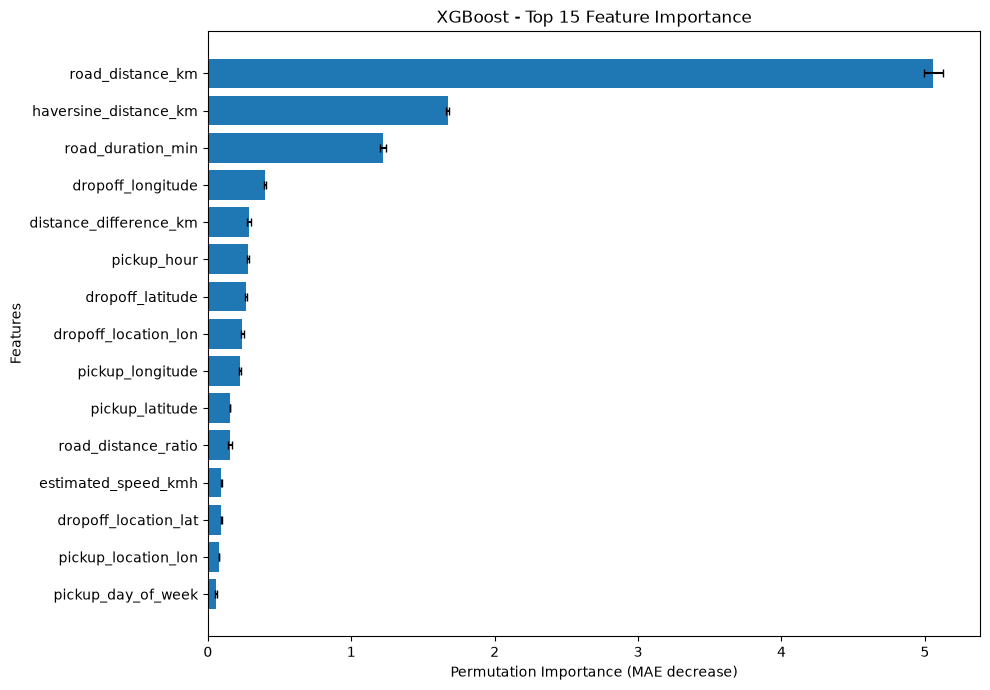

In [57]:

import pandas as pd
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "Feature": [
        "road_distance_km",
        "haversine_distance_km",
        "road_duration_min",
        "dropoff_longitude",
        "distance_difference_km",
        "pickup_hour",
        "dropoff_latitude",
        "dropoff_location_lon",
        "pickup_longitude",
        "pickup_latitude",
        "road_distance_ratio",
        "estimated_speed_kmh",
        "dropoff_location_lat",
        "pickup_location_lon",
        "pickup_day_of_week"
    ],
    "Importance": [
        5.059727, 1.671170, 1.222784, 0.399684, 0.286803,
        0.277466, 0.267972, 0.241590, 0.224607, 0.155346,
        0.154968, 0.094658, 0.092781, 0.077734, 0.056951
    ],
    "Std": [
        0.068182, 0.010871, 0.022843, 0.005298, 0.011660,
        0.007475, 0.008261, 0.011501, 0.005454, 0.001269,
        0.014205, 0.000874, 0.003257, 0.001171, 0.006987
    ]
})

# Plot feature importance
plot_df = importance_df.sort_values("Importance")

plt.figure(figsize=(10, 7))

plt.barh(
    plot_df["Feature"],
    plot_df["Importance"],
    xerr=plot_df["Std"],
    capsize=3
)

plt.xlabel("Permutation Importance (MAE decrease)")
plt.ylabel("Features")
plt.title("XGBoost - Top 15 Feature Importance")
plt.tight_layout()


# Save chart
plt.savefig(
    image_dir / "feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [58]:
print("Saved:", (image_dir / "feature_importance.png").exists())

Saved: True


Key observations
1. Road distance: Shuffling it increases MAE by approximately $5.06. This is substantial.
2. Haversine distance: Also contributes significantly, increasing MAE by $1.67.
3. Road duration: Adds useful predictive information, increasing MAE by $1.22.
4. Geographical coordinates: Pickup and dropoff locations contribute additional information.
5. Pickup hour: Time of day also helps predict fares.
Both methods identify the same top three features.  

One technical consideration: correlated features can share predictive information, so permutation importance may underestimate the individual contribution of some features.  
2. What have we achieved?
Our original objective was to investigate whether road-network distance improves taxi fare prediction compared with straight-line distance.  

Our findings strongly support the value of road distance in this model.  

However, we haven't yet isolated its improvement over a model using Haversine distance alone. That would be a useful additional experiment later.


# Residual analysis
Now let's investigate where our XGBoost model makes mistakes.  

A residual is the difference between the actual fare and predicted fare.  

In [29]:
# Create prediction analysis DataFrame
df_predictions = pd.DataFrame({
    "actual_fare": y_test,
    "predicted_fare": y_pred_xgb
})

# Calculate residuals
df_predictions["residual"] = (
    df_predictions["actual_fare"] -
    df_predictions["predicted_fare"]
)

df_predictions["absolute_error"] = (
    df_predictions["residual"].abs()
)

print("Residual Statistics:")
display(df_predictions["residual"].describe())

print("\nAbsolute Error Statistics:")
display(df_predictions["absolute_error"].describe())

Residual Statistics:


count    39136.000000
mean         0.196407
std          4.000568
min        -64.119003
25%         -1.122947
50%         -0.272077
75%          0.941250
max        159.117010
Name: residual, dtype: float64


Absolute Error Statistics:


count    3.913600e+04
mean     1.845288e+00
std      3.554989e+00
min      4.768372e-07
25%      4.958029e-01
50%      1.063388e+00
75%      2.023401e+00
max      1.591170e+02
Name: absolute_error, dtype: float64

Investigate the 10 worst predictions  
We don't need to investigate thousands of records. Let's inspect only the 10 trips with the largest absolute prediction errors.

In [30]:
# Combine predictions with important input features
df_error_analysis = df_predictions.join(
    X_test[
        [
            "road_distance_km",
            "haversine_distance_km",
            "road_duration_min",
            "passenger_count",
            "pickup_hour"
        ]
    ]
)

# Get 10 largest prediction errors
worst_predictions = df_error_analysis.nlargest(
    10,
    "absolute_error"
)

display(
    worst_predictions[
        [
            "actual_fare",
            "predicted_fare",
            "residual",
            "absolute_error",
            "road_distance_km",
            "haversine_distance_km",
            "road_duration_min",
            "passenger_count",
            "pickup_hour"
        ]
    ]
)

,actual_fare,predicted_fare,residual,absolute_error,road_distance_km,haversine_distance_km,road_duration_min,passenger_count,pickup_hour
158740,192.33,33.212990,159.117010,159.117010,0.0000,0.000000,0.000000,2.0,15.0
159734,150.00,10.224695,139.775305,139.775305,0.0000,0.598372,0.000000,1.0,16.0
173005,230.00,117.683151,112.316849,112.316849,38.5590,37.989067,45.236667,2.0,4.0
156917,183.00,73.893486,109.106514,109.106514,0.0000,0.058804,0.000000,1.0,15.0
177495,113.66,14.875849,98.784151,98.784151,0.5285,0.127635,1.543333,1.0,4.0
194366,134.29,46.946304,87.343696,87.343696,0.0000,0.004431,0.000000,1.0,18.0
177648,206.38,121.077164,85.302836,85.302836,48.4861,60.100889,54.621667,1.0,17.0
168686,163.00,79.440765,83.559235,83.559235,39.4148,31.688286,47.238333,1.0,4.0
194579,180.00,99.592438,80.407562,80.407562,0.0000,0.003621,0.000000,1.0,15.0
189176,190.83,117.039734,73.790266,73.790266,48.4668,46.086169,54.451667,1.0,19.0


Measure the routing anomaly  
Let's check how widespread this problem is across the entire modelling dataset.

In [31]:
# Trips where OSRM distance is zero but Haversine is positive
zero_road_anomalies = df_model[
    (df_model["road_distance_km"] == 0) &
    (df_model["haversine_distance_km"] > 0)
]

print("Zero road distance with positive Haversine:",
      len(zero_road_anomalies))

print("\nPercentage of dataset:",
      round(len(zero_road_anomalies) / len(df_model) * 100, 4),
      "%")

print("\nFare statistics for these trips:")
print(zero_road_anomalies["fare_amount"].describe())

print("\nTop 10 fares:")
display(
    zero_road_anomalies.nlargest(10, "fare_amount")[
        [
            "fare_amount",
            "haversine_distance_km",
            "road_distance_km",
            "road_duration_min"
        ]
    ]
)

Zero road distance with positive Haversine: 257

Percentage of dataset: 0.1313 %

Fare statistics for these trips:
count    257.000000
mean      28.754669
std       38.411550
min        2.500000
25%        4.500000
50%        8.100000
75%       49.570000
max      196.000000
Name: fare_amount, dtype: float64

Top 10 fares:


,fare_amount,haversine_distance_km,road_distance_km,road_duration_min
21234,196.00,0.001259,0.0,0.0
156917,183.00,0.058804,0.0,0.0
194579,180.00,0.003621,0.0,0.0
153363,171.35,0.000418,0.0,0.0
159734,150.00,0.598372,0.0,0.0
194366,134.29,0.004431,0.0,0.0
152622,132.33,0.001713,0.0,0.0
77709,130.00,0.008493,0.0,0.0
21985,129.57,0.000334,0.0,0.0
51364,120.00,0.001029,0.0,0.0


What these results tell us  
There are two possible situations:  
- Very small Haversine distances: Pickup and dropoff coordinates may be slightly different but snap to the same road-network location in OSRM. A zero road distance can occur in this situation.  
- Larger Haversine distances: A zero road distance is suspicious because two geographically separated points should not normally produce a zero-length route.  
For example:  

| Haversine | Road distance | Assessment |
| --- | --- | --- |
| 0.001 km | 0 km | Possibly coordinate snapping |
| 0.059 km | 0 km | Needs attention |
| 0.598 km | 0 km | Strong routing anomaly |   

Separate minor and significant anomalies
Let's use 100 metres as an initial investigation threshold.

In [32]:
# Separate zero-road-distance trips by Haversine distance
minor_anomalies = zero_road_anomalies[
    zero_road_anomalies["haversine_distance_km"] <= 0.1
]

significant_anomalies = zero_road_anomalies[
    zero_road_anomalies["haversine_distance_km"] > 0.1
]

print("Total zero-road anomalies:", len(zero_road_anomalies))

print("\nHaversine distance <= 100 metres:",
      len(minor_anomalies))

print("Haversine distance > 100 metres:",
      len(significant_anomalies))

print("\nSignificant anomaly statistics:")
print(
    significant_anomalies[
        [
            "haversine_distance_km",
            "fare_amount"
        ]
    ].describe()
)

Total zero-road anomalies: 257

Haversine distance <= 100 metres: 153
Haversine distance > 100 metres: 104

Significant anomaly statistics:
       haversine_distance_km  fare_amount
count             104.000000   104.000000
mean                1.232852    14.550673
std                 1.955876    24.508184
min                 0.100478     2.500000
25%                 0.333463     4.900000
50%                 0.650819     7.300000
75%                 1.114224    10.500000
max                13.004471   150.000000


# Our decision
I recommend treating all 257 records as having unreliable OSRM routing results.  

| Category	| Records	| Treatment |
| --- | --- | --- |
| Haversine distance ≤ 100 metres	| 153	| Flag unreliable routing |
| Haversine distance > 100 metres	| 104	| Flag unreliable routing |
| Total	| 257	| Preserve trips, mark routing features missing |

We will:
- Keep all 257 taxi trips.
- Set unreliable OSRM distance and duration to missing.
- Recalculate missing-value indicators.
- Impute using training-set medians later.
This is better than teaching the model that these trips genuinely had zero road distance.

In [33]:
# Identify unreliable OSRM results
anomaly_mask = (
    (df_model["road_distance_km"] == 0) &
    (df_model["haversine_distance_km"] > 0)
)

print("Unreliable OSRM records:", anomaly_mask.sum())

# Preserve an explicit quality indicator
df_model["osrm_zero_distance_anomaly"] = (
    anomaly_mask.astype(int)
)

# Mark unreliable routing outputs as missing
routing_features = [
    "road_distance_km",
    "road_duration_min",
    "road_distance_ratio",
    "distance_difference_km",
    "estimated_speed_kmh"
]

df_model.loc[anomaly_mask, routing_features] = np.nan

# Update missing-value indicators
df_model["osrm_route_missing"] = (
    df_model["road_distance_km"].isnull()
).astype(int)

df_model["road_distance_ratio_missing"] = (
    df_model["road_distance_ratio"].isnull()
).astype(int)

df_model["estimated_speed_missing"] = (
    df_model["estimated_speed_kmh"].isnull()
).astype(int)

Unreliable OSRM records: 257


In [34]:
print("Dataset shape:", df_model.shape)

print("\nUnreliable routing records:")
print(df_model["osrm_zero_distance_anomaly"].sum())

print("\nMissing routing features:")
print(df_model[routing_features].isnull().sum())

print("\nMissing-value indicators:")
print(
    df_model[
        [
            "osrm_route_missing",
            "road_distance_ratio_missing",
            "estimated_speed_missing"
        ]
    ].sum()
)

Dataset shape: (195680, 34)

Unreliable routing records:
257

Missing routing features:
road_distance_km           258
road_duration_min          258
road_distance_ratio       2231
distance_difference_km     258
estimated_speed_kmh       2274
dtype: int64

Missing-value indicators:
osrm_route_missing              258
road_distance_ratio_missing    2231
estimated_speed_missing        2274
dtype: int64


>>Important: Because we've corrected the feature data, our previous XGBoost and Random Forest models are no longer the final models. We'll rebuild the train/test datasets and retrain them using the corrected features.

In [35]:
# Sort chronologically
df_model = df_model.sort_values(
    "pickup_datetime"
).reset_index(drop=True)

# Target variable
y = df_model["fare_amount"].copy()

# Exclude identifiers, target and technical columns
exclude_columns = [
    "key",
    "fare_amount",
    "has_nonpositive_fare",
    "route_id",
    "status",
    "pickup_datetime",
    "pickup_datetime_ny"
]

# Predictor features
X = df_model.drop(columns=exclude_columns)

print("Feature matrix:", X.shape)
print("Target:", y.shape)
print("\nFeatures:")
print(X.columns.tolist())

Feature matrix: (195680, 27)
Target: (195680,)

Features:
['passenger_count', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'haversine_distance_km', 'is_zero_distance', 'road_distance_km', 'road_duration_min', 'pickup_hour', 'pickup_day', 'pickup_day_of_week', 'pickup_month', 'pickup_year', 'is_weekend', 'is_rush_hour', 'road_distance_ratio', 'distance_difference_km', 'estimated_speed_kmh', 'pickup_location_lat', 'pickup_location_lon', 'dropoff_location_lat', 'dropoff_location_lon', 'osrm_route_missing', 'road_distance_ratio_missing', 'estimated_speed_missing', 'osrm_zero_distance_anomaly']


In [36]:
split_index = int(len(df_model) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("Training:", X_train.shape, y_train.shape)
print("Testing:", X_test.shape, y_test.shape)

print("\nTraining period:")
print(df_model["pickup_datetime"].iloc[0],
      "to",
      df_model["pickup_datetime"].iloc[split_index - 1])

print("\nTesting period:")
print(df_model["pickup_datetime"].iloc[split_index],
      "to",
      df_model["pickup_datetime"].iloc[-1])

Training: (156544, 27) (156544,)
Testing: (39136, 27) (39136,)

Training period:
2009-01-01 01:15:22+00:00 to 2014-02-15 11:59:00+00:00

Testing period:
2014-02-15 12:13:30+00:00 to 2015-06-30 23:40:39+00:00


Apply median imputation again

In [37]:
from sklearn.impute import SimpleImputer

# Create median imputer
imputer = SimpleImputer(strategy="median")

# Fit only on training data
X_train_imputed = imputer.fit_transform(X_train)

# Apply training medians to test data
X_test_imputed = imputer.transform(X_test)

# Convert back to DataFrames
X_train = pd.DataFrame(
    X_train_imputed,
    columns=X.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    X_test_imputed,
    columns=X.columns,
    index=X_test.index
)

In [38]:
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining missing values:",
      X_train.isnull().sum().sum())

print("Testing missing values:",
      X_test.isnull().sum().sum())

print("\nTraining infinite values:",
      np.isinf(X_train.to_numpy()).sum())

print("Testing infinite values:",
      np.isinf(X_test.to_numpy()).sum())

Training shape: (156544, 27)
Testing shape: (39136, 27)

Training missing values: 0
Testing missing values: 0

Training infinite values: 0
Testing infinite values: 0


# Retrain XGBoost
Let's start with XGBoost because it was our best-performing model previously.

In [39]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=7,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=42,
    n_jobs=6
)

# Train
xgb_model.fit(X_train, y_train)

# Predict
y_pred_xgb = xgb_model.predict(X_test)

print("Corrected XGBoost training completed!")

Corrected XGBoost training completed!


In [40]:
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)

rmse_xgb = np.sqrt(
    mean_squared_error(y_test, y_pred_xgb)
)

r2_xgb = r2_score(y_test, y_pred_xgb)

print("\nCorrected XGBoost Performance")
print("-----------------------------")
print(f"MAE:  ${mae_xgb:.4f}")
print(f"RMSE: ${rmse_xgb:.4f}")
print(f"R2 Score: {r2_xgb:.4f}")


Corrected XGBoost Performance
-----------------------------
MAE:  $1.8502
RMSE: $3.9802
R2 Score: 0.8770


# Retrain Random Forest

In [41]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

# Train
rf_model.fit(X_train, y_train)

# Predict
y_pred_rf = rf_model.predict(X_test)

print("Corrected Random Forest training completed!")

Corrected Random Forest training completed!


In [42]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

r2_rf = r2_score(y_test, y_pred_rf)

print("\nCorrected Random Forest Performance")
print("-----------------------------------")
print(f"MAE:  ${mae_rf:.4f}")
print(f"RMSE: ${rmse_rf:.4f}")
print(f"R2 Score: {r2_rf:.4f}")


Corrected Random Forest Performance
-----------------------------------
MAE:  $1.9278
RMSE: $4.0618
R2 Score: 0.8719


# Retrain Baseline and Linear Regression

In [43]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

# Baseline
baseline_model = DummyRegressor(strategy="median")
baseline_model.fit(X_train, y_train)
y_pred_baseline = baseline_model.predict(X_test)

# Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)

print("Baseline and Linear Regression retraining completed!")

Baseline and Linear Regression retraining completed!


In [44]:
models = {
    "Baseline": y_pred_baseline,
    "Linear Regression": y_pred_linear,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb
}

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

final_comparison = pd.DataFrame(results).sort_values(
    "MAE"
).reset_index(drop=True)

display(final_comparison.round(4))

,Model,MAE,RMSE,R2 Score
0,XGBoost,1.8502,3.9802,0.8770
1,Random Forest,1.9278,4.0618,0.8719
2,Linear Regression,2.5220,4.9674,0.8084
3,Baseline,6.5982,12.3760,-0.1893


# Visualize actual vs predicted fares

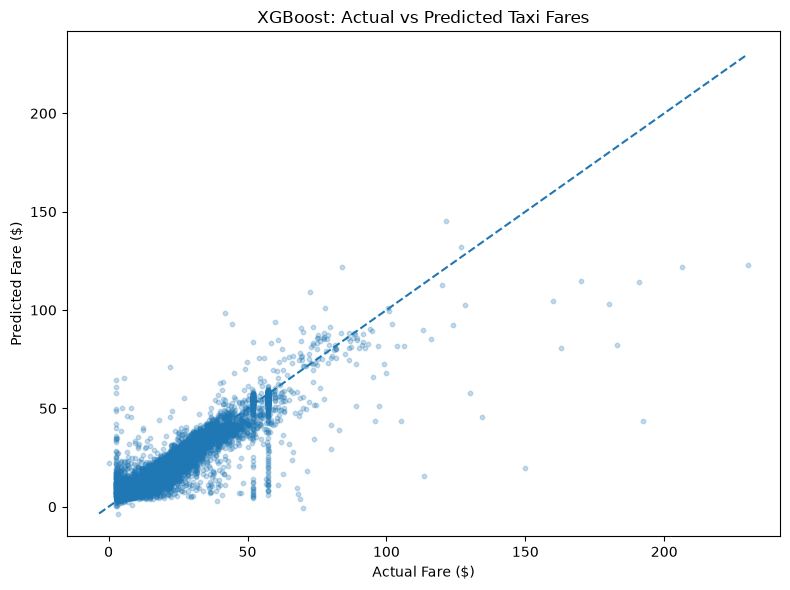

<Figure size 640x480 with 0 Axes>

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_xgb,
    alpha=0.25,
    s=10
)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred_xgb.min())
max_value = max(y_test.max(), y_pred_xgb.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Fare ($)")
plt.ylabel("Predicted Fare ($)")
plt.title("XGBoost: Actual vs Predicted Taxi Fares")

plt.tight_layout()
plt.show()



from pathlib import Path

image_dir = Path("../reports/images")
image_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    image_dir / "actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

In [55]:
print("Saved:", (image_dir / "actual_vs_predicted.png").exists())

Saved: True


# Evaluate performance by fare range

In [46]:
# Create evaluation DataFrame using corrected XGBoost predictions
df_evaluation = pd.DataFrame({
    "actual_fare": y_test,
    "predicted_fare": y_pred_xgb
})

df_evaluation["absolute_error"] = (
    df_evaluation["actual_fare"] -
    df_evaluation["predicted_fare"]
).abs()

df_evaluation["fare_range"] = pd.cut(
    df_evaluation["actual_fare"],
    bins=[0, 10, 20, 30, 50, 100, float("inf")],
    labels=[
        "$0–10",
        "$10–20",
        "$20–30",
        "$30–50",
        "$50–100",
        "Above $100"
    ],
    include_lowest=True
)

fare_performance = (
    df_evaluation
    .groupby("fare_range", observed=False)
    .agg(
        trip_count=("actual_fare", "count"),
        average_actual_fare=("actual_fare", "mean"),
        average_predicted_fare=("predicted_fare", "mean"),
        MAE=("absolute_error", "mean")
    )
    .round(3)
)

display(fare_performance)

,trip_count,average_actual_fare,average_predicted_fare,MAE
fare_range,,,,
$0–10,21493,6.893,7.557000,1.135
$10–20,12304,13.979,13.341000,1.851
$20–30,2580,24.196,22.353001,3.578
$30–50,1701,37.393,35.441002,4.380
$50–100,1032,58.520,53.714001,6.886
Above $100,26,141.231,87.946999,55.558


1. Strong performance on common fares

Approximately 86% of test trips have fares between $0 and $20. Our model performs particularly well in this range.

2. High-fare underprediction

For fares above $100:
- Actual average: $141.23
- Predicted average: $87.95
- Average underprediction: approximately $53.28.
3. Small high-fare sample

Only 26 test trips have fares above $100. We shouldn't overfit the model just to improve this small group.

My recommendation is to retain XGBoost as our current champion and document its limitations rather than artificially improving its test results.

# Save the trained model
Now let's save our trained XGBoost model so we can reuse it without training again.

>> python -m pip install joblib  
>> import joblib from pathlib import Path

In [47]:
import joblib
from pathlib import Path

In [48]:
# Create models directory
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

# Create model bundle
model_bundle = {
    "model": xgb_model,
    "imputer": imputer,
    "feature_columns": X.columns.tolist(),
    "model_name": "XGBoost",
    "target": "fare_amount"
}

# Save model bundle
model_path = model_dir / "xgboost_taxi_fare_model.joblib"

joblib.dump(model_bundle, model_path)

print("Model saved successfully!")
print("Location:", model_path)
print("File size:", round(model_path.stat().st_size / (1024 * 1024), 2), "MB")

Model saved successfully!
Location: ..\models\xgboost_taxi_fare_model.joblib
File size: 3.01 MB


In [49]:
loaded_bundle = joblib.load(model_path)

print("Loaded model:", loaded_bundle["model_name"])
print("Number of features:", len(loaded_bundle["feature_columns"]))

print("Model verification:",
      loaded_bundle["model"] is not None)

Loaded model: XGBoost
Number of features: 27
Model verification: True


>>Important: This saves the trained model and imputer, not the entire feature-engineering pipeline. For deployment, we'll also need to reproduce the datetime, coordinate and OSRM feature transformations.

# Test the saved model
We need to verify that the loaded model produces the same predictions as our original trained model.  

This is important because eventually we'll use this saved model in a prediction application.  

In [50]:
# Recover test features before imputation
X_test_raw = X.iloc[split_index:].copy()

print("Raw test shape:", X_test_raw.shape)
print("Missing values:", X_test_raw.isnull().sum().sum())

Raw test shape: (39136, 27)
Missing values: 560


In [51]:
loaded_imputer = loaded_bundle["imputer"]

X_test_transformed = loaded_imputer.transform(X_test_raw)

X_test_transformed = pd.DataFrame(
    X_test_transformed,
    columns=loaded_bundle["feature_columns"],
    index=X_test_raw.index
)

In [52]:
loaded_model = loaded_bundle["model"]

y_pred_loaded = loaded_model.predict(X_test_transformed)

print("First 10 predictions:")
print(y_pred_loaded[:10])

First 10 predictions:
[ 9.385751   7.8193636  6.9562173  4.7524867  9.860266   7.497975
  9.183174  11.611485   8.916736  10.07439  ]


In [53]:
prediction_difference = np.abs(
    y_pred_xgb - y_pred_loaded
)

print("Maximum prediction difference:",
      prediction_difference.max())

print("Predictions identical:",
      np.allclose(y_pred_xgb, y_pred_loaded))

Maximum prediction difference: 0.0
Predictions identical: True


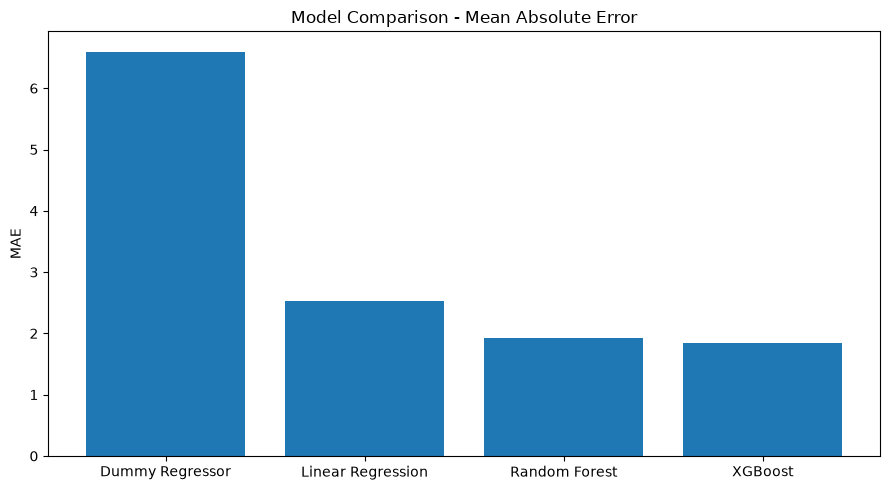

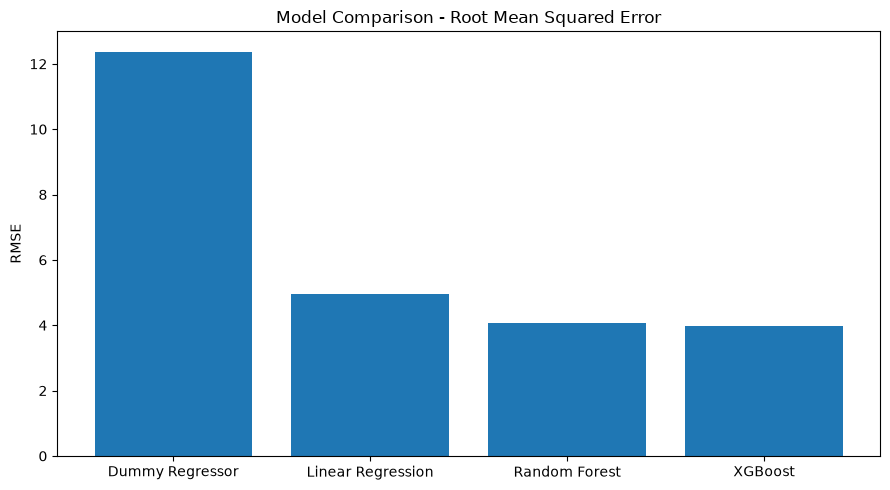

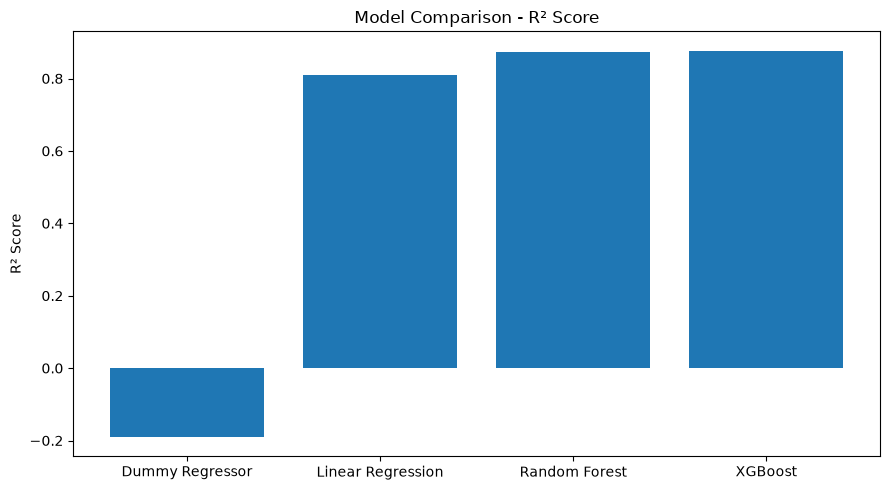

In [59]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Create image directory
image_dir = Path("../reports/images")
image_dir.mkdir(parents=True, exist_ok=True)

# Model evaluation results
model_results = pd.DataFrame({
    "Model": [
        "Dummy Regressor",
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],
    "MAE": [6.5982, 2.5220, 1.9278, 1.8502],
    "RMSE": [12.3760, 4.9674, 4.0618, 3.9802],
    "R2": [-0.1893, 0.8084, 0.8719, 0.8770]
})

# Plot MAE
plt.figure(figsize=(9, 5))
plt.bar(model_results["Model"], model_results["MAE"])
plt.ylabel("MAE")
plt.title("Model Comparison - Mean Absolute Error")
plt.tight_layout()
plt.savefig(image_dir / "model_comparison_mae.png",
            dpi=300, bbox_inches="tight")
plt.show()

# Plot RMSE
plt.figure(figsize=(9, 5))
plt.bar(model_results["Model"], model_results["RMSE"])
plt.ylabel("RMSE")
plt.title("Model Comparison - Root Mean Squared Error")
plt.tight_layout()
plt.savefig(image_dir / "model_comparison_rmse.png",
            dpi=300, bbox_inches="tight")
plt.show()

# Plot R²
plt.figure(figsize=(9, 5))
plt.bar(model_results["Model"], model_results["R2"])
plt.ylabel("R² Score")
plt.title("Model Comparison - R² Score")
plt.tight_layout()
plt.savefig(image_dir / "model_comparison_r2.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [60]:
for file in image_dir.glob("model_comparison_*.png"):
    print(file.name, "-", round(file.stat().st_size / 1024, 2), "KB")

model_comparison_mae.png - 57.61 KB
model_comparison_r2.png - 65.97 KB
model_comparison_rmse.png - 63.85 KB
